In [1]:
import os,shutil,subprocess,sys,pathlib


In [2]:
os.makedirs("/content", exist_ok=True)
os.chdir("/content")
print("CWD set to:", os.getcwd())


CWD set to: /content


In [3]:
if os.path.isdir("/content/Zero-DCE"):
    shutil.rmtree("/content/Zero-DCE", ignore_errors=True)


In [4]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rawpy", "imageio", "opencv-python"], check=True)



CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'rawpy', 'imageio', 'opencv-python'], returncode=0)

In [5]:

subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Li-Chongyi/Zero-DCE.git"], check=True)

CompletedProcess(args=['git', 'clone', '--depth', '1', 'https://github.com/Li-Chongyi/Zero-DCE.git'], returncode=0)

In [6]:
code_dir = "/content/Zero-DCE/Zero-DCE_code"
print("Code dir exists?", os.path.isdir(code_dir))
print("Snapshot exists?", os.path.isfile(os.path.join(code_dir, "snapshots", "Epoch99.pth")))

Code dir exists? True
Snapshot exists? True


In [7]:
os.chdir(code_dir)
print("Now in:", os.getcwd())
print("Files here:", os.listdir(".")[:20])

import os, glob
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import model as model_mod

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__)
print("Using device:", device)

weight_path = "snapshots/Epoch99.pth"
assert os.path.isfile(weight_path), f"Missing weights: {weight_path}"


Now in: /content/Zero-DCE/Zero-DCE_code
Files here: ['Myloss.py', 'lowlight_test.py', 'lowlight_train.py', '.gitignore', 'dataloader.py', 'data', 'snapshots', 'model.py']
Torch: 2.14.1+cpu
Using device: cpu


Using model class: enhance_net_nopool
Loaded weights: snapshots/Epoch99.pth
Model ready.
data/test_data/DICM: 64 images


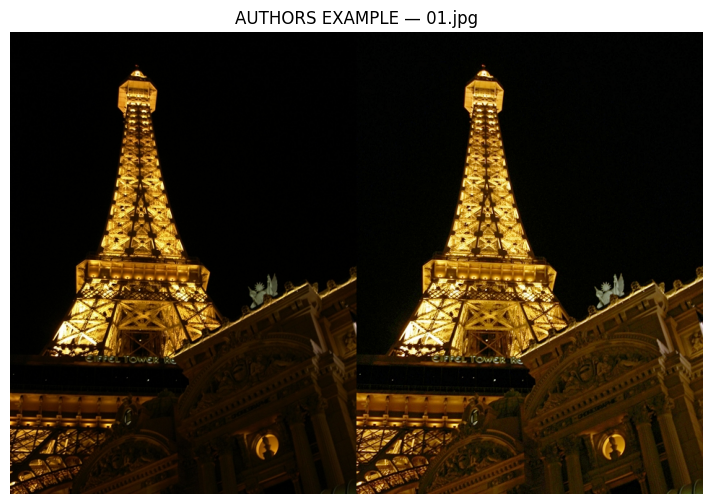

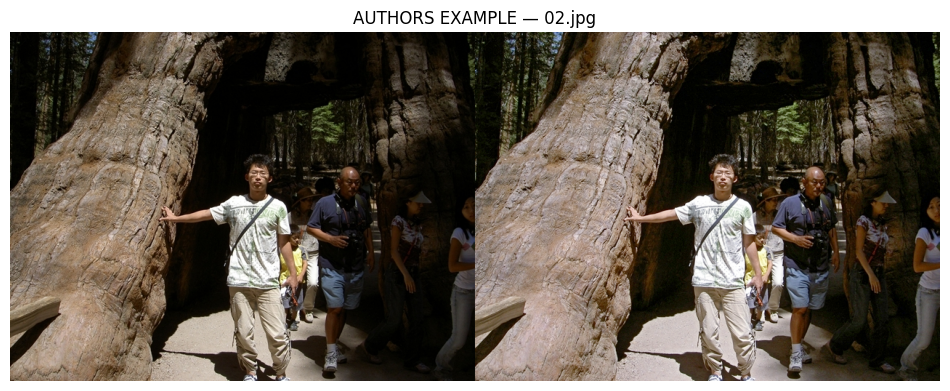

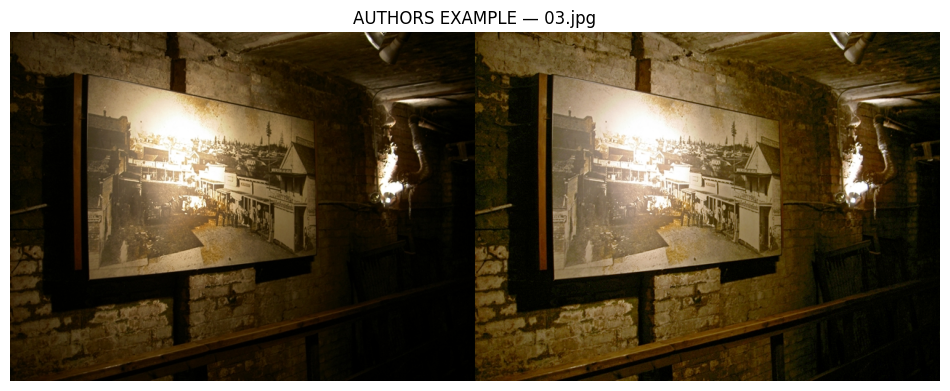

data/test_data/LIME: 0 images


Saving thumb.jpg to thumb.jpg


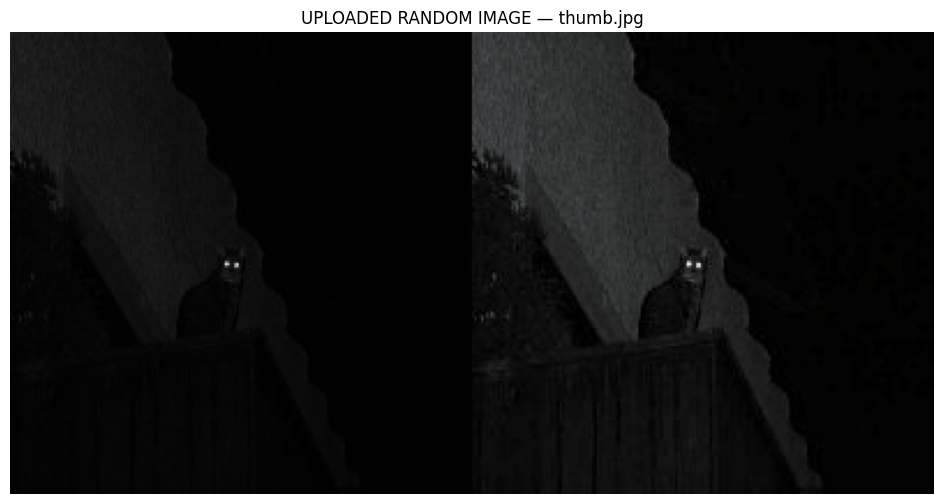

In [8]:

candidates = []
for name, obj in model_mod.__dict__.items():
    if isinstance(obj, type) and issubclass(obj, nn.Module) and obj is not nn.Module:
        candidates.append((name, obj))
assert candidates, "No torch.nn.Module classes found in model.py"

preferred = ["enhance", "enhancement", "dce", "net", "network"]
def score(name):
    nl = name.lower()
    return sum(1 for p in preferred if p in nl)

candidates.sort(key=lambda x: score(x[0]), reverse=True)
ModelClassName, ModelClass = candidates[0]
print("Using model class:", ModelClassName)

net = ModelClass().to(device).eval()

ckpt = torch.load(weight_path, map_location=device)
if isinstance(ckpt, dict) and "state_dict" in ckpt:
    ckpt = ckpt["state_dict"]
state = {k.replace("module.", ""): v for k, v in ckpt.items()} if isinstance(ckpt, dict) else ckpt
net.load_state_dict(state, strict=False)
print("Loaded weights:", weight_path)

def enhance_pil(pil_img):
    pil_img = pil_img.convert("RGB")
    arr = np.asarray(pil_img).astype(np.float32) / 255.0
    x = torch.from_numpy(arr).permute(2,0,1).unsqueeze(0).to(device)
    with torch.no_grad():
        y = net(x)
    y = y[0] if isinstance(y, (tuple, list)) else y
    y = y.squeeze(0).permute(1,2,0).detach().cpu().numpy()
    y = np.clip(y * 255.0, 0, 255).astype(np.uint8)
    return Image.fromarray(y)

def show_side_by_side(pil_orig, pil_enh, title="", max_w=1400):
    o = pil_orig.convert("RGB")
    e = pil_enh.convert("RGB")
    if e.size != o.size:
        e = e.resize(o.size, Image.BICUBIC)

    w, h = o.size
    scale = min(1.0, max_w / float(w*2))
    if scale < 1.0:
        new_size = (int(w*scale), int(h*scale))
        o = o.resize(new_size, Image.BICUBIC)
        e = e.resize(new_size, Image.BICUBIC)
        w, h = o.size

    canvas = Image.new("RGB", (w*2, h))
    canvas.paste(o, (0,0))
    canvas.paste(e, (w,0))

    plt.figure(figsize=(12, 6))
    plt.imshow(canvas)
    plt.axis("off")
    plt.title(title)
    plt.show()

print("Model ready.")

import glob, os
from PIL import Image

folders = ["data/test_data/DICM", "data/test_data/LIME"]

for folder in folders:
    paths = sorted(glob.glob(os.path.join(folder, "*")))
    paths = [p for p in paths if p.lower().endswith((".jpg",".jpeg",".png"))]
    print(f"{folder}: {len(paths)} images")

    for p in paths[:3]:
        orig = Image.open(p).convert("RGB")
        enh  = enhance_pil(orig)
        show_side_by_side(orig, enh, title=f"AUTHORS EXAMPLE — {os.path.basename(p)}")

from google.colab import files
from PIL import Image
import io, os

uploaded = files.upload()

for name, b in uploaded.items():
    ext = os.path.splitext(name)[1].lower()
    if ext not in [".jpg", ".jpeg", ".png"]:
        print("Skipping (not jpg/png):", name)
        continue

    orig = Image.open(io.BytesIO(b)).convert("RGB")
    enh  = enhance_pil(orig)
    show_side_by_side(orig, enh, title=f"UPLOADED RANDOM IMAGE — {name}")

from google.colab import files
import io, os, glob, zipfile
import numpy as np
from PIL import Image

uploaded = files.upload()


In [9]:

for k in list(uploaded.keys()):
    if k.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(uploaded[k]), "r") as z:
            z.extractall("npy_inputs")
        print("Extracted zip -> npy_inputs/")

In [10]:
uploaded = files.upload()

Saving raw_image_1568_16.npy to raw_image_1568_16.npy
Saving isp_pipeline.py to isp_pipeline.py


In [11]:
assert os.path.isfile("isp_pipeline.py"), "Please upload isp_pipeline.py in this cell."

import isp_pipeline
from isp_pipeline import isp_apply
print("Loaded isp_apply OK")

Loaded isp_apply OK


In [12]:
print(os.getcwd())

/content/Zero-DCE/Zero-DCE_code


Found .npy files: 2
['raw_image_1568_16.npy', 'raw_image_1568_16.npy']


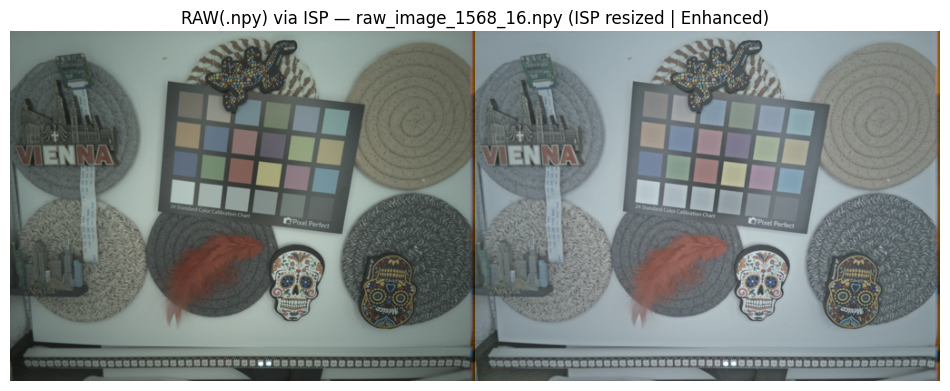

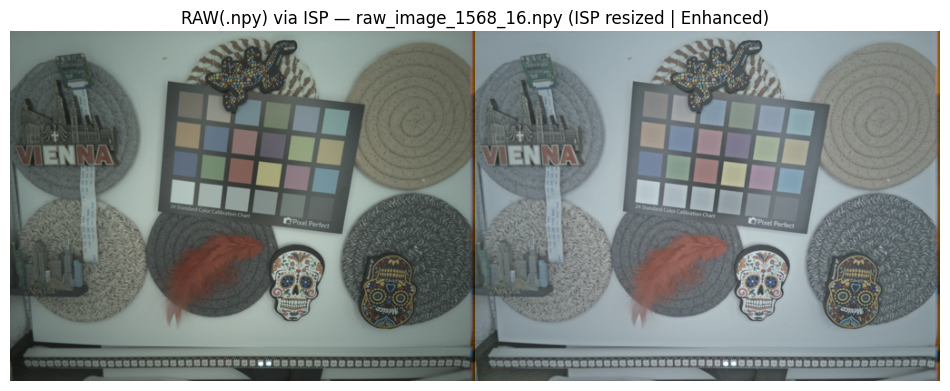

In [13]:

import os
import glob
import numpy as np
from PIL import Image

params = dict(
    bit_depth=16,
    black_level=4100,
    cfa_pattern="gbrg",
    wp=[1.25, 1.0, 1.67],
    gamma=2.2
)

def resize_keep_aspect(pil_img: Image.Image, max_side: int) -> Image.Image:
    w, h = pil_img.size
    s = max(w, h)

    if s <= max_side:
        return pil_img

    scale = max_side / float(s)
    new_w = int(round(w * scale))
    new_h = int(round(h * scale))

    return pil_img.resize((new_w, new_h), Image.BICUBIC)



npy_files = glob.glob("*.npy") + glob.glob("**/*.npy", recursive=True)

print("Found .npy files:", len(npy_files))
print(npy_files)

max_side = 512

for p in sorted(npy_files):
    raw = np.load(p)


    rgb = isp_apply(raw, **params)

    rgb_u8 = np.clip(rgb * 255.0, 0, 255).astype(np.uint8)
    isp_img = Image.fromarray(rgb_u8).convert("RGB")

    isp_small = resize_keep_aspect(isp_img, max_side)


    enh_small = enhance_pil(isp_small)

    show_side_by_side(
        isp_small,
        enh_small,
        title=f"RAW(.npy) via ISP — {os.path.basename(p)} "
              f"(ISP resized | Enhanced)"
    )

In [14]:
import matplotlib.pyplot as plt

In [15]:
def add_gaussian_noise(image, noise_level=0.05):

    # Convert image to NumPy array
    img = np.asarray(image).astype(np.float32) / 255.0

    # Generate Gaussian noise
    noise = np.random.normal(
        0,
        noise_level,
        img.shape
    )

    # Add noise
    noisy = img + noise

    # Keep values between 0 and 1
    noisy = np.clip(noisy, 0, 1)

    # Convert back to image
    noisy = (noisy * 255).astype(np.uint8)

    return Image.fromarray(noisy)

In [16]:
def show_three_images(original, noisy, enhanced, title=""):

    original = original.convert("RGB")
    noisy = noisy.convert("RGB")
    enhanced = enhanced.convert("RGB")

    # Use original image size
    size = original.size

    noisy = noisy.resize(size)
    enhanced = enhanced.resize(size)

    w, h = size

    # Create combined image
    canvas = Image.new("RGB", (w * 3, h))

    canvas.paste(original, (0, 0))
    canvas.paste(noisy, (w, 0))
    canvas.paste(enhanced, (w * 2, 0))

    plt.figure(figsize=(18, 6))
    plt.imshow(canvas)
    plt.axis("off")
    plt.title(title)
    plt.show()

In [17]:
from google.colab import files
import io

uploaded = files.upload()

for name, data in uploaded.items():

    # Read image
    original = Image.open(io.BytesIO(data)).convert("RGB")

    print("Image:", name)
    print("Size:", original.size)


Saving noisy.jpeg to noisy.jpeg
Image: noisy.jpeg
Size: (543, 565)


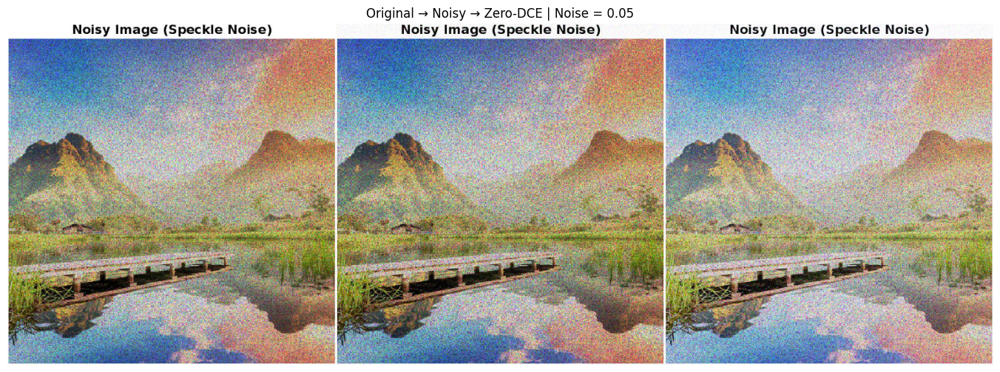

In [18]:
noise_level = 0.05

noisy = add_gaussian_noise(
    original,
    noise_level=noise_level
)

enhanced = enhance_pil(noisy)

show_three_images(
    original,
    noisy,
    enhanced,
    title=f"Original → Noisy → Zero-DCE | Noise = {noise_level}"
)


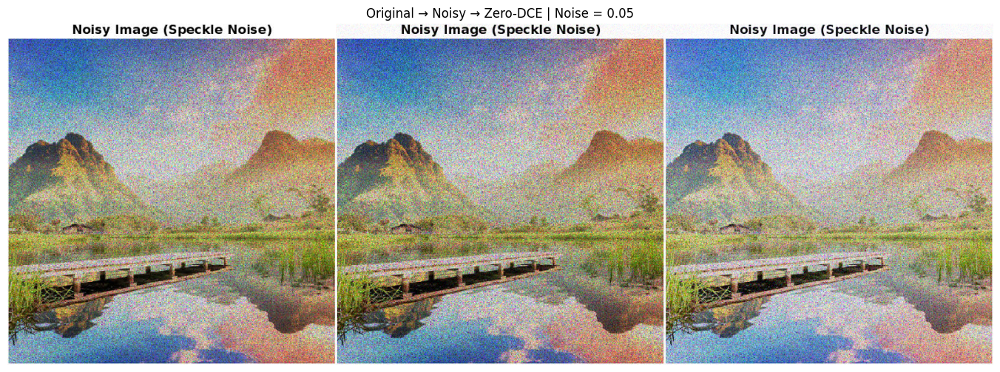

In [19]:
noise_level = 0.05

noisy = add_gaussian_noise(
    original,
    noise_level=noise_level
)

enhanced = enhance_pil(noisy)

show_three_images(
    original,
    noisy,
    enhanced,
    title=f"Original → Noisy → Zero-DCE | Noise = {noise_level}"
)

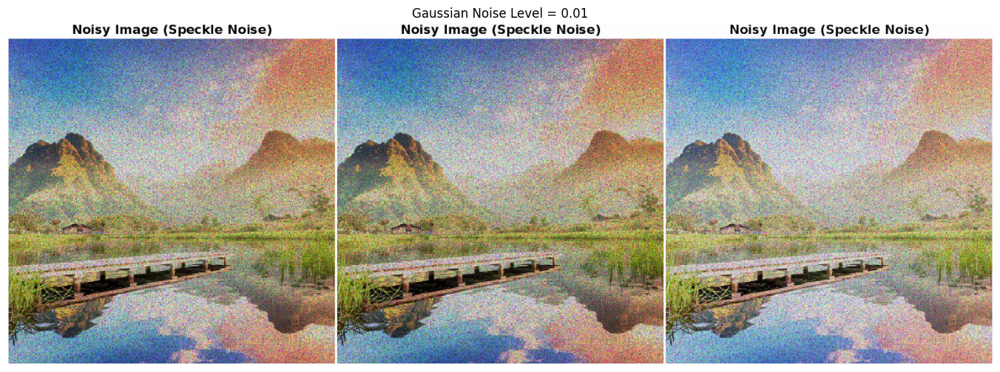

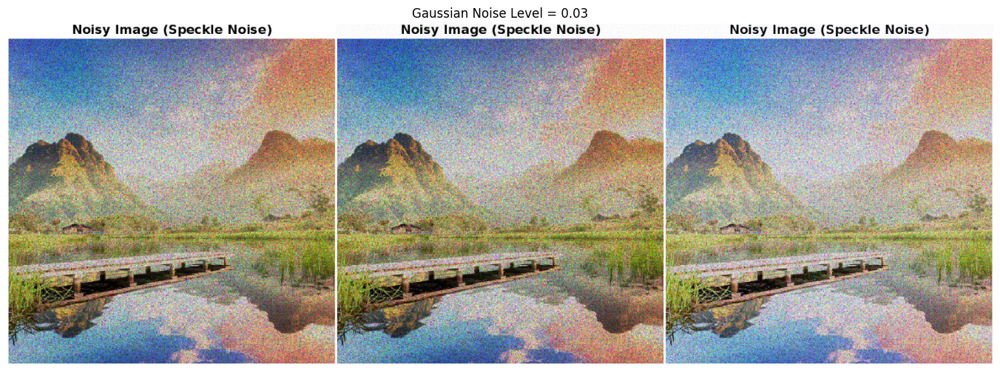

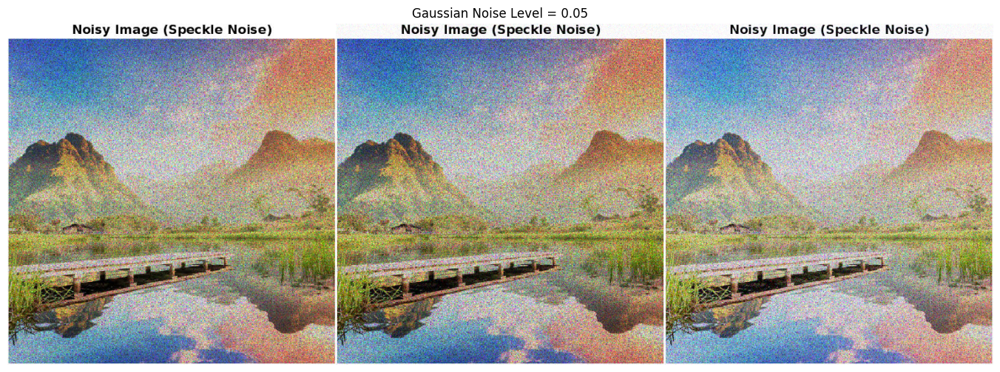

In [ ]:
noise_levels = [0.01, 0.03, 0.05, 0.10, 0.20]

for level in noise_levels:

    noisy = add_gaussian_noise(
        original,
        noise_level=level
    )

    enhanced = enhance_pil(noisy)

    show_three_images(
        original,
        noisy,
        enhanced,
        title=f"Gaussian Noise Level = {level}"
    )

In [ ]:
folders = [
    "data/test_data/DICM",
    "data/test_data/LIME"
]

noise_level = 0.05

for folder in folders:

    paths = sorted(
        glob.glob(os.path.join(folder, "*"))
    )

    paths = [
        p for p in paths
        if p.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    print("\nFolder:", folder)
    print("Images found:", len(paths))

    # Test first 3 images
    for p in paths[:3]:

        original = Image.open(p).convert("RGB")

        noisy = add_gaussian_noise(
            original,
            noise_level=noise_level
        )

        enhanced = enhance_pil(noisy)

        show_three_images(
            original,
            noisy,
            enhanced,
            title=f"{os.path.basename(p)} | Noise = {noise_level}"
        )

In [ ]:
noise_levels = [0.01, 0.03, 0.05, 0.10, 0.20]

folder = "data/test_data/DICM"

paths = sorted(
    glob.glob(os.path.join(folder, "*"))
)

paths = [
    p for p in paths
    if p.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

# Use first image
original = Image.open(paths[0]).convert("RGB")

for level in noise_levels:

    noisy = add_gaussian_noise(
        original,
        noise_level=level
    )

    enhanced = enhance_pil(noisy)

    show_three_images(
        original,
        noisy,
        enhanced,
        title=f"Noise Level = {level}"
    )

In [ ]:
output_dir = "/content/noise_experiment"
os.makedirs(output_dir, exist_ok=True)

noise_level = 0.05

noisy = add_gaussian_noise(
    original,
    noise_level=noise_level
)

enhanced = enhance_pil(noisy)

noisy.save(
    os.path.join(output_dir, "noisy.png")
)

enhanced.save(
    os.path.join(output_dir, "zero_dce_noisy.png")
)

print("Images saved in:", output_dir)

In [ ]:
import os, sys, subprocess
subprocess.run("pip -q install scikit-image", shell=True)
if not os.path.exists("Zero-DCE_extension"):
    subprocess.run("git clone -q https://github.com/Li-Chongyi/Zero-DCE_extension.git", shell=True)
DCE_DIR = "Zero-DCE_extension/Zero-DCE++"
sys.path.insert(0, DCE_DIR)
import model  # official Zero-DCE++ model.py

In [ ]:
TRAIN_DIR      = "/content/lowlight_train"
EVAL_DIR       = "/content/lowlight_eval"
PAIRED_LOW_DIR = "/content/paired/low"
PAIRED_REF_DIR = "/content/paired/normal"
CURVE_CKPT     = f"{DCE_DIR}/snapshots_Zero-DCE++/Epoch99.pth"
DENOISER_CKPT  = "/content/checkpoints/denoiser.pth"

EPOCHS, BATCH_SIZE, TRAIN_SIZE, LR = 15, 8, 256, 1e-3
EVAL_SIZE = 512


In [ ]:
import csv
from pathlib import Path
from PIL import Image
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

device = "cuda" if torch.cuda.is_available() else "cpu"
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
print("Device:", device)

In [ ]:
NOISE_LEVELS = [
    (0, "gaussian",    [5/255, 10/255, 20/255]),
    (1, "poisson",     [1/120, 1/60, 1/30]),
    (2, "salt_pepper", [0.01, 0.03, 0.05]),
]

def add_noise(x, noise_id, strength):
    out = x.clone()
    for i in range(x.shape[0]):
        kind, s = int(noise_id[i].item()), float(strength[i].item())
        if kind == 0:
            out[i] = x[i] + torch.randn_like(x[i]) * s
        elif kind == 1:
            peak = max(1.0 / max(s, 1e-6), 1.0)
            out[i] = torch.poisson(torch.clamp(x[i], 0, 1) * peak) / peak
        elif kind == 2:
            mask = torch.rand_like(x[i, :1]) < s
            salt = torch.rand_like(x[i, :1]) < 0.5
            impulse = torch.where(salt, torch.ones_like(salt, dtype=x.dtype),
                                  torch.zeros_like(salt, dtype=x.dtype))
            out[i] = torch.where(mask.expand_as(x[i]), impulse.expand_as(x[i]), x[i])
        else:
            raise ValueError(f"Unknown noise id {kind}")
    return out.clamp(0, 1)

def sample_noise_conditions(batch_size, dev):
    noise_id = torch.randint(0, 3, (batch_size,), device=dev)
    ranges = {0: (5/255, 20/255), 1: (1/120, 1/30), 2: (0.01, 0.05)}
    strengths = [float(torch.empty(1).uniform_(*ranges[k]).item()) for k in noise_id.tolist()]
    return noise_id, torch.tensor(strengths, device=dev, dtype=torch.float32)

In [ ]:
class NoiseConditionedDenoiser(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(7, width, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(width, 3, 3, padding=1))

    def forward(self, noisy, noise_id, strength):
        b, _, h, w = noisy.shape
        type_map = F.one_hot(noise_id.long(), num_classes=3).to(noisy.dtype)[:, :, None, None].expand(b, 3, h, w)
        strength_map = strength.view(b, 1, 1, 1).expand(b, 1, h, w).to(noisy.dtype)
        feats = torch.cat([noisy, type_map, strength_map], dim=1)
        return (noisy - self.body(feats)).clamp(0, 1)

class NoiseAwareZeroDCEPP(nn.Module):
    def __init__(self, scale_factor=1, denoiser_width=32):
        super().__init__()
        self.denoiser = NoiseConditionedDenoiser(width=denoiser_width)
        self.enhancer = model.enhance_net_nopool(scale_factor)

    def forward(self, noisy, noise_id, strength):
        denoised = self.denoiser(noisy, noise_id, strength)
        enhanced, curve_map = self.enhancer(denoised)
        return enhanced, curve_map, denoised

In [ ]:
def to_uint8(t):
    return (t.detach().clamp(0, 1).cpu().squeeze(0).permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)

def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in EXTS)

def load_denoiser(path):
    den = NoiseConditionedDenoiser().to(device)
    ck = torch.load(path, map_location=device)
    den.load_state_dict(ck["model"] if "model" in ck else ck)
    return den.eval()

def load_enhancer(path):
    enh = model.enhance_net_nopool(scale_factor=1).to(device)
    enh.load_state_dict(torch.load(path, map_location=device))
    return enh.eval()

def save_csv(rows, out):
    if not rows:
        raise RuntimeError("No rows to save (no images found / no filename matches).")
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    with open(out, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=rows[0].keys())
        w.writeheader(); w.writerows(rows)
    print(f"Saved {len(rows)} rows to {out}")

In [ ]:
import glob, os, random, shutil

# find the sample low-light images that came with the cloned repo
imgs = sorted(p for p in glob.glob("/content/Zero-DCE*/**/data/test_data/**/*", recursive=True)
              if p.lower().endswith((".jpg", ".jpeg", ".png")))
print("Images found:", len(imgs))

# split 80% train / 20% eval
random.seed(0); random.shuffle(imgs)
n_eval = max(1, int(0.2 * len(imgs)))
splits = {"/content/lowlight_eval": imgs[:n_eval], "/content/lowlight_train": imgs[n_eval:]}

for folder, paths in splits.items():
    os.makedirs(folder, exist_ok=True)
    for p in paths:
        # prefix with the subfolder name (DICM, LIME...) so file names don't collide
        name = os.path.basename(os.path.dirname(p)) + "_" + os.path.basename(p)
        shutil.copy(p, os.path.join(folder, name))
    print(folder, "->", len(os.listdir(folder)), "images")

In [ ]:
class ImageFolderDataset(Dataset):
    def __init__(self, folder, size=256):
        self.paths = list_images(folder)
        if not self.paths:
            raise RuntimeError(f"No images found under: {folder}")
        self.tf = transforms.Compose([transforms.Resize((size, size)),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor()])
        print(f"Found {len(self.paths)} images")
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return self.tf(im.convert("RGB"))

def train_denoiser():
    dl = DataLoader(ImageFolderDataset(TRAIN_DIR, TRAIN_SIZE), batch_size=BATCH_SIZE,
                    shuffle=True, num_workers=2, pin_memory=(device == "cuda"))
    net = NoiseConditionedDenoiser().to(device)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    Path(DENOISER_CKPT).parent.mkdir(parents=True, exist_ok=True)
    for epoch in range(EPOCHS):
        net.train(); running = 0.0
        for clean in dl:
            clean = clean.to(device)
            nid, s = sample_noise_conditions(clean.shape[0], device)
            noisy = add_noise(clean, nid, s)
            restored = net(noisy, nid, s)
            loss = torch.sqrt((restored - clean).pow(2) + 1e-6).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            running += loss.item()
        print(f"Epoch {epoch+1:03d}/{EPOCHS}  loss={running/max(len(dl),1):.6f}")
        torch.save({"model": net.state_dict(), "epoch": epoch + 1}, DENOISER_CKPT)

train_denoiser()

In [ ]:
CKPT = "/content/checkpoints/denoiser.pth"
print("Checkpoint exists?", os.path.isfile(CKPT))

In [ ]:
den = NoiseConditionedDenoiser().to(device)
den.load_state_dict(torch.load(CKPT, map_location=device)["model"]); den.eval()

def run_pipelines(clean_t, nid, s):
    ids = torch.tensor([nid], device=device)
    st = torch.tensor([s], device=device, dtype=torch.float32)
    torch.manual_seed(2026)
    noisy = add_noise(clean_t, ids, st)
    with torch.no_grad():
        dn = den(noisy, ids, st)
    return noisy, enhance_tensor(noisy), dn, enhance_tensor(dn)

img_path = val_paths[0]
clean_t = to_tensor(Image.open(img_path))
for nid, name, lv in NOISE_LEVELS:
    noisy, base, dn, prop = run_pipelines(clean_t, nid, lv[2])
    fig, ax = plt.subplots(1, 5, figsize=(22, 5))
    for a, im, t in zip(ax, [clean_t, noisy, base, dn, prop],
        ["Original low-light", f"Noisy ({name})", "Baseline: Zero-DCE only",
         "Denoised", "Proposed: Denoise + Zero-DCE"]):
        a.imshow(to_pil(im)); a.set_title(t); a.axis("off")
    plt.show()

In [ ]:
import sys, importlib
sys.modules.pop("model", None)
sys.path = [p for p in sys.path if p != DCE_DIR]
sys.path.insert(0, DCE_DIR)
import model
importlib.reload(model)
print(model.__file__)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
NOISE_NAMES = ["gaussian", "poisson", "salt_pepper"]
RANGES = {0: (5/255, 20/255), 1: (1/120, 1/30), 2: (0.01, 0.05)}


In [ ]:
enh = load_enhancer(CURVE_CKPT)

In [ ]:
val_paths = list_images(EVAL_DIR)

def to_tensor(pil, size=256):
    pil = pil.convert("RGB").resize((size, size), Image.BICUBIC)
    return transforms.ToTensor()(pil).unsqueeze(0).to(device)

def to_pil(t):
    return Image.fromarray(to_uint8(t)) if torch.is_tensor(t) else t

@torch.no_grad()
def enhance_tensor(x):
    out, _ = enh(x)
    return out.clamp(0, 1)



In [ ]:
class NoiseIdentifier(nn.Module):
    """Input: noisy image. Output: noise-type logits (3) + normalised strength (0..1)."""
    def __init__(self, w=32):
        super().__init__()
        self.feat = nn.Sequential(
            nn.Conv2d(6, w, 3, padding=1), nn.ReLU(True),
            nn.Conv2d(w, w, 3, padding=1), nn.ReLU(True),
            nn.Conv2d(w, 2*w, 3, stride=2, padding=1), nn.ReLU(True),
            nn.Conv2d(2*w, 2*w, 3, padding=1), nn.ReLU(True),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.cls = nn.Linear(2*w, 3)
        self.reg = nn.Sequential(nn.Linear(2*w, 1), nn.Sigmoid())
    def forward(self, x):
        hp = x - F.avg_pool2d(x, 3, 1, 1)           # high-pass residual exposes the noise
        f = self.feat(torch.cat([x, hp], 1))
        return self.cls(f), self.reg(f).squeeze(1)

def norm_strength(nid, s):
    lo = torch.tensor([RANGES[k][0] for k in nid.tolist()], device=s.device)
    hi = torch.tensor([RANGES[k][1] for k in nid.tolist()], device=s.device)
    return (s - lo) / (hi - lo)

def denorm_strength(nid, u):
    lo = torch.tensor([RANGES[k][0] for k in nid.tolist()], device=u.device)
    hi = torch.tensor([RANGES[k][1] for k in nid.tolist()], device=u.device)
    return lo + u.clamp(0, 1) * (hi - lo)

IDENT_CKPT = "/content/checkpoints/identifier.pth"
def train_identifier(epochs=30):
    dl = DataLoader(ImageFolderDataset(TRAIN_DIR, TRAIN_SIZE), batch_size=BATCH_SIZE, shuffle=True)
    net = NoiseIdentifier().to(device)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for ep in range(epochs):
        net.train(); tot, correct, n = 0.0, 0, 0
        for clean in dl:
            clean = clean.to(device)
            nid, s = sample_noise_conditions(clean.shape[0], device)
            noisy = add_noise(clean, nid, s)
            logits, u = net(noisy)
            loss = F.cross_entropy(logits, nid) + 5 * F.mse_loss(u, norm_strength(nid, s))
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(nid); n += len(nid)
            correct += (logits.argmax(1) == nid).sum().item()
        print(f"Epoch {ep+1:02d}/{epochs}  loss={tot/n:.4f}  train acc={correct/n:.3f}")
    torch.save(net.state_dict(), IDENT_CKPT)
    return net.eval()

ident = train_identifier()

In [ ]:
def psnr_ssim(a, b):
    a, b = to_uint8(a), to_uint8(b)
    return (peak_signal_noise_ratio(a, b, data_range=255),
            structural_similarity(a, b, channel_axis=2, data_range=255))

rows, y_true, y_pred = [], [], []
torch.manual_seed(2026)
for p in val_paths:
    clean = to_tensor(Image.open(p))
    ref_enh = enhance_tensor(clean)                 # what Zero-DCE gives on a noise-free image
    for nid, name, levels in NOISE_LEVELS:
        for lv in levels:
            ids = torch.tensor([nid], device=device)
            st = torch.tensor([lv], device=device, dtype=torch.float32)
            noisy = add_noise(clean, ids, st)
            with torch.no_grad():
                logits, u = ident(noisy)
                pid = logits.argmax(1)
                pst = denorm_strength(pid, u)
                den_out = den(noisy, pid, pst)       # denoiser gets identified type, not ground truth
            base = enhance_tensor(noisy)             # baseline: Zero-DCE only
            prop = enhance_tensor(den_out)           # proposed: identify + denoise + Zero-DCE
            y_true.append(nid); y_pred.append(pid.item())
            r = dict(image=p.name, noise=name, level=lv, id_correct=int(pid.item() == nid))
            r["noisy_psnr"], r["noisy_ssim"] = psnr_ssim(noisy, clean)
            r["den_psnr"], r["den_ssim"] = psnr_ssim(den_out, clean)
            r["base_psnr"], r["base_ssim"] = psnr_ssim(base, ref_enh)
            r["prop_psnr"], r["prop_ssim"] = psnr_ssim(prop, ref_enh)
            rows.append(r)

save_csv(rows, "/content/results/metrics.csv")
df = pd.DataFrame(rows)

print(f"\nNoise-type identification accuracy: {df.id_correct.mean()*100:.2f}%")
print(df.groupby("noise").id_correct.mean().mul(100).round(2).rename("ID acc %"))
print()
print(df.groupby("noise")[["noisy_psnr","den_psnr","base_psnr","prop_psnr",
                           "noisy_ssim","den_ssim","base_ssim","prop_ssim"]].mean().round(3))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=NOISE_NAMES).plot()
plt.title("Noise type identification"); plt.show()

In [ ]:
img = to_tensor(Image.open(val_paths[0]))
for nid, name, levels in NOISE_LEVELS:
    ids = torch.tensor([nid], device=device); st = torch.tensor([levels[2]], device=device, dtype=torch.float32)
    noisy = add_noise(img, ids, st)
    with torch.no_grad():
        lg, u = ident(noisy); pid = lg.argmax(1); dn = den(noisy, pid, denorm_strength(pid, u))
    fig, ax = plt.subplots(1, 5, figsize=(22, 5))
    for a, im, t in zip(ax, [img, noisy, enhance_tensor(noisy), dn, enhance_tensor(dn)],
        ["Original low-light", f"Noisy ({name}) -> predicted: {NOISE_NAMES[pid.item()]}",
         "Baseline: Zero-DCE only", "Denoised", "Proposed: Identify + Denoise + Zero-DCE"]):
        a.imshow(to_pil(im)); a.set_title(t, fontsize=9); a.axis("off")
    plt.show()